<a href="https://colab.research.google.com/github/anguzamwasia/Coding-for-Disaster-and-Risk-Management/blob/main/Guide_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing Libraries needed

In [ ]:
#BLOCK 1: INSTALLING LIBRARIES
!pip install --quiet osmnx geopandas folium matplotlib requests
print("All libraries have been installed successfully")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.5 MB/s eta 0:00:00
All libraries have been installed successfully


Importin Libraries and Setting up the study location
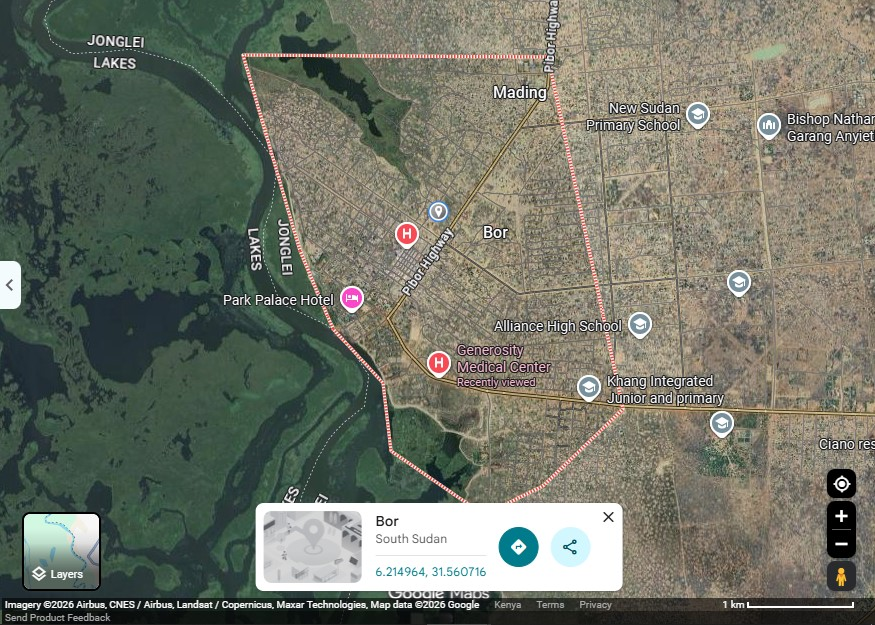

In [ ]:
#BLOCK 2: IMPORTING LIBRARIES AND STUDY LOCATION SETUP
import osmnx as ox # Downloads roads, rivers, and buildings from OpenStreetMap
import geopandas as gpd # Works with map data i.e Excel table
import folium # Draws  interactive and clickable maps in the web browser
import requests # Connects to the internet to download live alerts i.e wildfire, flooding, earthquakes
from shapely.geometry import Point, LineString # Imports spatial geometry types from Shapely for single or multiple locations

#Coordinates for Bor South, South Sudan
BOR_LAT = 6.21
BOR_LON = 31.56

#How wide to scan in Bor South
SCAN_RADIUS_METERS = 10000
print(f"Study Area : Bor South, South Sudan at ({BOR_LAT}, {BOR_LON})")
print(f"Scan Radius: {SCAN_RADIUS_METERS / 1000}km around Bor South")

Study Area : Bor South, South Sudan at (6.21, 31.56)
Scan Radius: 10.0km around Bor South


Downloading River Nile Waterway

In [ ]:
#BLOCK 3: DOWNLOAD RIVER NILE WATERWAYS VIA OSMNX
print("Scanning OSM for River Nile Waterway")
#Fetch all waterways: rivers, canals, streams, swamps within 10km of Bor South
nile_waterways = ox.features_from_point(
    (BOR_LAT, BOR_LON),
    dist=SCAN_RADIUS_METERS,
    tags={"waterway": True} # True pulls all rivers, canals, streams, swamps within 10km of Bor South
)
nile_waterways = nile_waterways[nile_waterways.geometry.type.isin(["LineString", "MultiLineString"])]
nile_waterways[["name", "waterway", "geometry"]].head(5)

Scanning OSM for River Nile Waterway


name waterway  \
element id                                                  
way     73274023   Bahr al Jabal (Mountain Nile)    river   
        73274043                             NaN   stream   
        253210180                            NaN    ditch   
        253210202                            NaN    ditch   
        253215369                            NaN    ditch   

                                                            geometry  
element id                                                            
way     73274023   LINESTRING (31.51245 6.07863, 31.51228 6.07933...  
        73274043   LINESTRING (31.51785 6.09339, 31.51832 6.0936,...  
        253210180  LINESTRING (31.54831 6.21877, 31.54768 6.21838...  
        253210202  LINESTRING (31.54842 6.21885, 31.54955 6.21959...  
        253215369  LINESTRING (31.55073 6.20989, 31.55049 6.20969...